In [1]:
import numpy as np
import os
import sys
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq
import warnings
from scipy.integrate import quad, IntegrationWarning

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from utils.raytracing import calculate_source_position
from kgeo.kerr_raytracing_ana import raytrace_ana

Welcome to eht-imaging! v 1.2.10 



/home/canoziia/MyProject/PHYS/EHT_ZC/.pixi/envs/default/lib/python3.12/site-packages/ehtim/__init__.py:58: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [ ]:
# --- 1. 定义黑洞和观测者参数 ---
# 黑洞自旋参数 (0 <= a <= 1)
a = 0.9375

# 观测者倾角 (单位：度)
# 0度为正对自旋轴，90度为从赤道面观测
inc = 17 / 180 * np.pi  # 将度转换为弧度

# --- 2. 定义观测者图像平面上的坐标 ---
# 您可以替换这里的 alpha 和 beta 值为您自己程序中的特定坐标点
# 这里我们创建一个 100x100 的网格作为示例
fov = 46.2262 / 2  # 视场范围 (-20M 到 20M)
npix = 100  # 图像平面的像素数（单边）
x = np.linspace(-fov, fov, npix)
y = np.linspace(-fov, fov, npix)
alpha, beta = np.meshgrid(x, y)

# --- 3. 调用 kgeo 的光线追踪函数 ---
# 这是 kgeo 的核心功能，它接收黑洞参数和观测者坐标
# 并返回一个包含光线追踪结果的字典
# [1]: 这是一个基于 Gralla & Lupsasca 2019 公式的解析光线追踪程序
out = raytrace_ana(a=a, observer_coords=[0, 500.0, inc, 0], image_coords=[alpha, beta])

calculating preliminaries...
integrating in theta...3.40 s
integrating in r...4.25 s
plotting data...
Error plotting data!
done!   7.685013055801392  seconds!


In [ ]:
r_at_theta_pi_2 = np.full((npix, npix), np.nan)  # 初始化一个与图像平面大小相同的数组
# r_at_theta_pi_2=np.zeros((npix, npix))  # 初始化为零
img_size = npix
for xi in range(img_size):
    for yi in range(img_size):
        thetas = out.th_s[:, xi, yi]
        if len(thetas) > 0:
            diffs = thetas - np.pi / 2
            # mask 中 True 表示 θ<π/2
            mask = diffs > 0
            if mask.any():
                # 找到第一个满足条件的索引
                first_idx = np.where(mask)[0][0]
                first_theta_1 = thetas[first_idx]
                first_theta_2 = (
                    thetas[first_idx - 1] if first_idx - 1 >= 0 else first_theta_1
                )

                _r_1 = out.r_s[first_idx, xi, yi]
                _r_2 = out.r_s[first_idx - 1, xi, yi] if first_idx - 1 >= 0 else _r_1
                r_at_theta_pi_2[xi, yi] = (
                    _r_1 * np.abs(first_theta_2) + _r_2 * np.abs(first_theta_1)
                ) / (np.abs(first_theta_2) + np.abs(first_theta_1))

In [ ]:
from functools import lru_cache


@lru_cache(maxsize=None)  # None 表示无限缓存
def _calculate_source_position(x, y):
    print("1")
    obs_rho = np.sqrt(x**2 + y**2)
    obs_phi = np.arctan2(x, y)  # 特别注意这个phi是和y轴的夹角，顺时针增大
    try:
        return calculate_source_position(
            obs_rho=obs_rho,
            obs_phi=obs_phi,
            r_o=500,
            theta_o=17 / 180 * np.pi,
            a=0.9375,
            M=1.0,
        )  # phi_s又是逆时针的)
    except Exception as e:
        print(e)
        return (200.0, 0.0, 0.0)


_v_calculate_source_position = np.vectorize(_calculate_source_position)

In [ ]:
x_coords = np.tile(np.linspace(-49.5, 49.5, 100), (100, 1)) * 46.2262 / 99
y_coords = (
    np.tile(np.linspace(-49.5, 49.5, 100).reshape(100, 1), (1, 100)) * 46.2262 / 99
)
r_s, phi_s, t_s = _v_calculate_source_position(x_coords, y_coords)

1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1


/home/canoziia/MyProject/PHYS/EHT_ZC/utils/raytracing.py:164: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  G_phi_2, _ = quad(integrand_G_phi, theta_c, theta_o, -sign_theta)


1
1
1
1
1
1
1
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源theta_s，可能是因为参数设置不当。
1
光线无法朔源the

/home/canoziia/MyProject/PHYS/EHT_ZC/utils/raytracing.py:193: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  _I_r = lambda _r_s: quad(integrand_I_r, _r_s, r_o, sign_r)[0] - G_theta


1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1


/home/canoziia/MyProject/PHYS/EHT_ZC/utils/raytracing.py:187: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  I_t_1, _ = quad(integrand_I_t, r_s, r_c, sign_r)


1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1


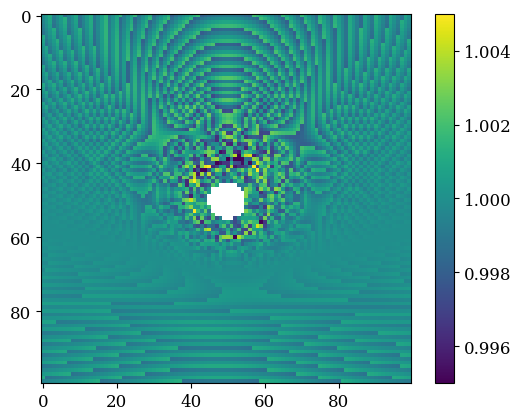

In [ ]:
plt.imshow(r_s / r_at_theta_pi_2)
plt.colorbar()
plt.clim(0.995, 1.005)

In [ ]:
# ------------------ 示例用法 ------------------
spin_param = 0.9
mass_param = 1.0
# 案例1: 预期有转折点的轨迹
print("--- 案例 1: 预期有转折点的轨迹 ---")
obs_rho = 5.0
obs_phi = 1.0
r_observer = 50.0
theta_observer = np.deg2rad(17)

print(
    f"输入参数: obs_rho={obs_rho}, obs_phi={obs_phi}, r_o={r_observer}, θ_o={np.rad2deg(theta_observer):.2f}°\n"
)

source_position = calculate_source_position(
    obs_rho=obs_rho,
    obs_phi=obs_phi,
    r_o=r_observer,
    theta_o=theta_observer,
    a=spin_param,
    M=mass_param,
)

if source_position:
    r_source, phi_source, _ = source_position
    print(f"计算成功! 源位置 (r_s, φ_s): ({r_source:.4f}, {phi_source:.4f} rad)")
else:
    print("计算失败。")

print("\n" + "=" * 40 + "\n")

# 案例2: 预期路径更直接的轨迹
print("--- 案例 2: 预期路径更直接的轨迹 ---")
obs_rho = 5.0
obs_phi = np.pi + 0.1
r_observer = 50.0
theta_observer = np.deg2rad(17)

print(
    f"输入参数: obs_rho={obs_rho}, obs_phi={obs_phi}, r_o={r_observer}, θ_o={np.rad2deg(theta_observer):.2f}°\n"
)

source_position = calculate_source_position(
    obs_rho=obs_rho,
    obs_phi=obs_phi,
    r_o=r_observer,
    theta_o=theta_observer,
    a=spin_param,
    M=mass_param,
)

if source_position:
    r_source, phi_source, _ = source_position
    print(f"计算成功! 源位置 (r_s, φ_s): ({r_source:.4f}, {phi_source:.4f} rad)")
else:
    print("计算失败。")

--- 案例 1: 预期有转折点的轨迹 ---
输入参数: obs_rho=5.0, obs_phi=1.0, r_o=50.0, θ_o=17.00°

计算成功! 源位置 (r_s, φ_s): (3.5531, 1.9798 rad)


--- 案例 2: 预期路径更直接的轨迹 ---
输入参数: obs_rho=5.0, obs_phi=3.241592653589793, r_o=50.0, θ_o=17.00°

计算成功! 源位置 (r_s, φ_s): (4.3892, -0.1849 rad)


In [ ]:
calculate_ray_path_optimized(
    obs_rho=5, obs_phi=0, r_o=300, theta_o=60 / 180 * np.pi, a=0.9375, M=1.0
)

/tmp/ipykernel_1175264/3718237584.py:26: UserWarning: obs_phi已略微移动以避免奇点
  warnings.warn("obs_phi已略微移动以避免奇点")


(3.0992575556360444, -2.722875660649979)

In [ ]:
r_s, phi_s, t_s = calculate_source_position(
    obs_rho=obs_rho,
    obs_phi=obs_phi,
    r_o=r_observer,
    theta_o=theta_observer,
    a=spin_param,
    M=mass_param,
)

/tmp/ipykernel_1175264/4845503.py:26: UserWarning: obs_phi为0或π，可能导致计算不稳定。
  warnings.warn("obs_phi为0或π，可能导致计算不稳定。")


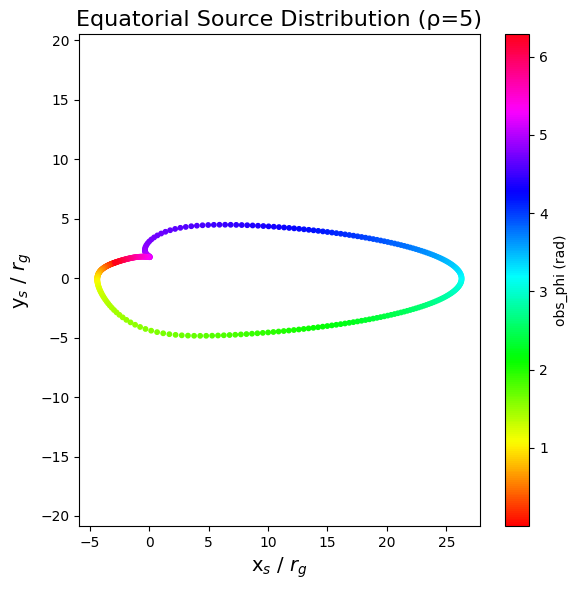

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 在赤道面上绘制 rho=5 时，obs_phi 从 0 到 2π 对应的源位置分布
phis = np.linspace(0.00013, 2 * np.pi + 0.00015, 360)
rs_src = []
phis_src = []

for phi in phis:
    # print(f"Processing phi: {phi:f} rad")
    res = calculate_ray_path_optimized(
        obs_rho=5, obs_phi=phi, r_o=300, theta_o=80 / 180 * np.pi, a=-0.9375, M=1.0
    )
    if res is not None:
        r_s, phi_s = res
        rs_src.append(r_s)
        phis_src.append(phi_s)

rs_src = np.array(rs_src)
phis_src = np.array(phis_src)

# 转换到笛卡尔坐标
xs = rs_src * np.cos(phis_src)
ys = rs_src * np.sin(phis_src)

plt.figure(figsize=(6, 6))
sc = plt.scatter(xs, ys, c=phis[: len(xs)], cmap="hsv", s=10)
plt.xlabel("x$_s$ / $r_g$", fontsize=14)
plt.ylabel("y$_s$ / $r_g$", fontsize=14)
plt.title("Equatorial Source Distribution (ρ=5)", fontsize=16)
plt.axis("equal")
plt.colorbar(sc, label="obs_phi (rad)")
plt.tight_layout()
plt.show()

In [ ]:
(np.ones((16, 64, 64)) * np.arange(16)[:, np.newaxis, np.newaxis])[2]

array([[2., 2., 2., ..., 2., 2., 2.],
       [2., 2., 2., ..., 2., 2., 2.],
       [2., 2., 2., ..., 2., 2., 2.],
       ...,
       [2., 2., 2., ..., 2., 2., 2.],
       [2., 2., 2., ..., 2., 2., 2.],
       [2., 2., 2., ..., 2., 2., 2.]])

In [ ]:
import numpy as np


def estimate_cos_params(evpa_data):
    if evpa_data.shape[0] == 17:
        data_16 = evpa_data[1:]
    elif evpa_data.shape[0] == 16:
        data_16 = evpa_data

    N = 16
    X = np.sum(
        data_16
        * np.exp(-2j * np.pi * np.arange(N) / N).reshape(-1, *[1] * (data_16.ndim - 1))
    )
    A = 2 * np.abs(X) / N
    phi = np.angle(X)
    phi = (phi + np.pi) % (2 * np.pi) - np.pi

    return A, phi


# ===== 测试 =====
if __name__ == "__main__":
    N = 16
    A_true = 3.0
    phi_true = 2.8
    y = np.array([A_true * np.cos(2 * np.pi * n / N + phi_true) for n in range(N)])

    A_est, phi_est = estimate_cos_params(y)

    print("真实振幅:", A_true)
    print("估计振幅:", A_est)
    print("真实相位:", phi_true)
    print("估计相位:", phi_est)

真实振幅: 3.0
估计振幅: 3.0000000000000004
真实相位: 2.8
估计相位: 2.8


In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy.interpolate
import scipy.integrate
import scipy.stats as stats
from scipy.ndimage import gaussian_filter
from copy import deepcopy
from scipy import integrate, optimize
from statsmodels.stats.diagnostic import lilliefors

In [17]:
def fit_gaussian(d1arr, evpa_angle=False):
    if evpa_angle:
        pass
    else:
        stat, p_value = lilliefors(d1arr)
        # print(stat, p_value)
        return stat, p_value

In [ ]:
def plot_gaussian(data):
    """
    可视化一维高斯数据分布。

    该函数会执行以下操作：
    1. 绘制数据的直方图，并进行归一化处理。
    2. 使用scipy.stats.norm.fit()从数据中估算出最佳的高斯分布参数（均值和标准差）。
    3. 在直方图上叠加绘制拟合出的高斯分布概率密度函数(PDF)曲线。
    4. 添加标题、标签和图例，使图形信息完整。

    参数:
    data (array-like): 一个包含数值数据的一维数组或列表。
    """
    # 1. 使用scipy拟合数据，得到最匹配的均值(mu)和标准差(sigma)
    mu, sigma = stats.norm.fit(data)

    # 2. 绘制直方图
    # bins='auto' 会自动选择合适的柱子数量
    # density=True 是关键，它将直方图的高度归一化，使得总面积为1，从而可以与概率密度函数曲线叠加
    plt.hist(
        data, bins="auto", density=True, alpha=0.7, color="skyblue", label="数据直方图"
    )

    # 3. 绘制拟合的高斯分布PDF曲线
    # 创建一个x轴的取值范围，覆盖数据的主要区域
    xmin, xmax = plt.xlim()
    x = np.linspace(xmin, xmax, 100)
    # 使用计算出的mu和sigma生成高斯分布的PDF值
    p = stats.norm.pdf(x, mu, sigma)
    plt.plot(x, p, "k", linewidth=2, label="拟合的高斯曲线")

    # 4. 添加图形元素，使其更具可读性
    title = f"μ = {mu:.2f}, σ = {sigma:.2f}"
    plt.title(title)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)

    # 显示图形
    plt.show()

In [ ]:
np.asarray(stats.norm.fit([1, 2, 3]))

array([2.        , 0.81649658])

0.0011060177380829046


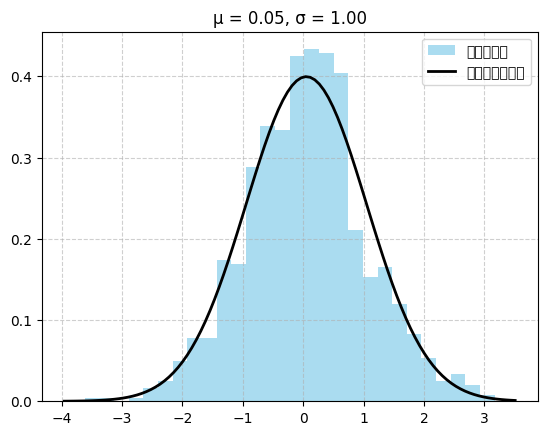

0.001053421595462258


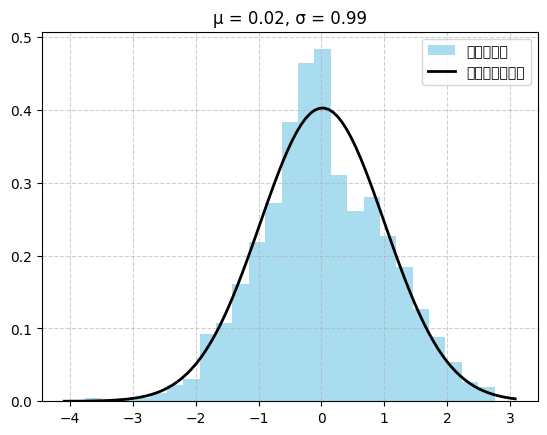

0.001278779425007243


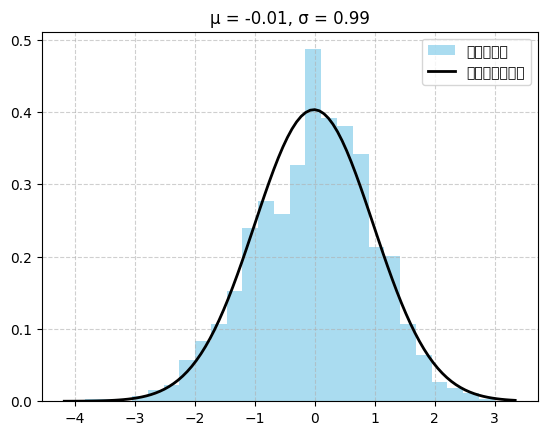

0.0015492289238052872


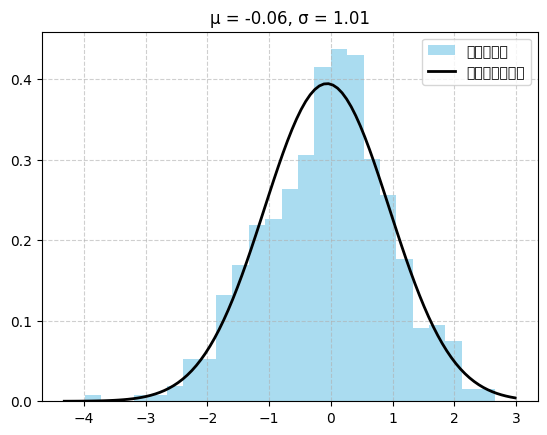

0.001998991094702655


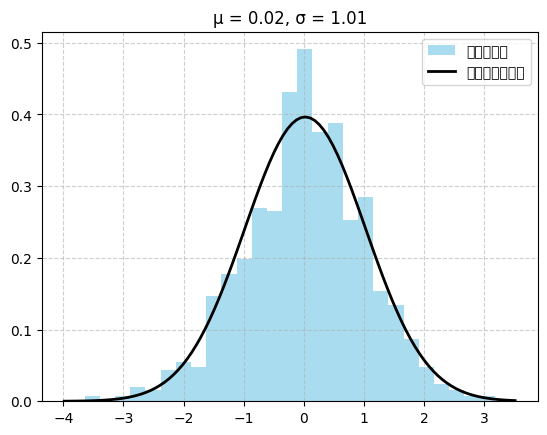

0.001362687159103247


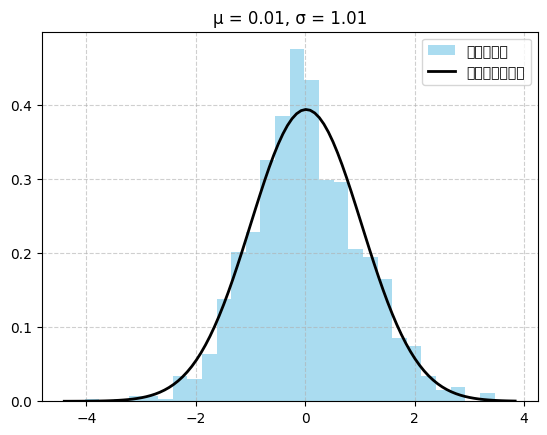

0.0017961889664071086


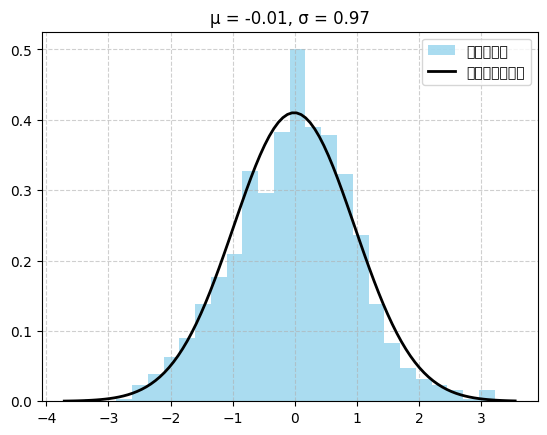

0.0019106993332368954


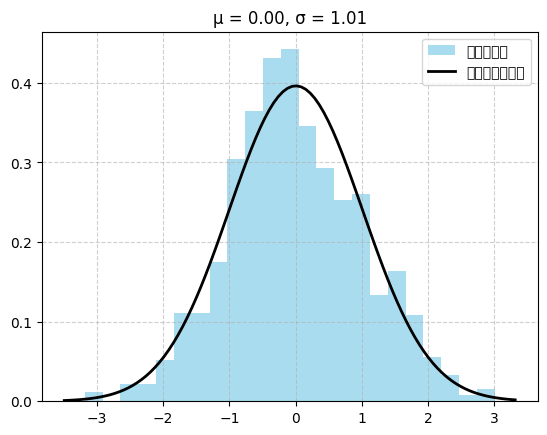

0.0009999999999998899


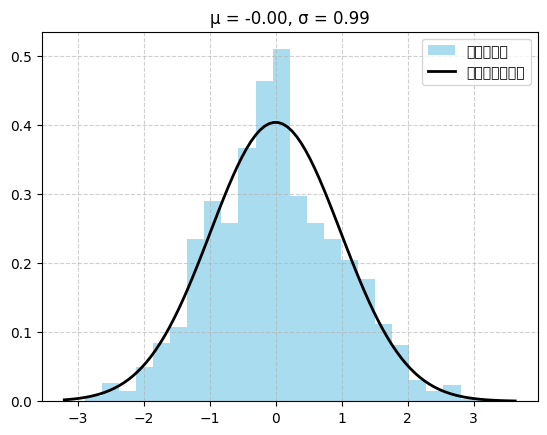

0.0009999999999998899


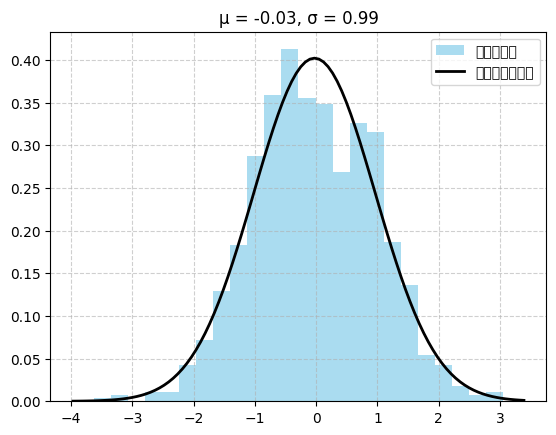

0.0009999999999998899


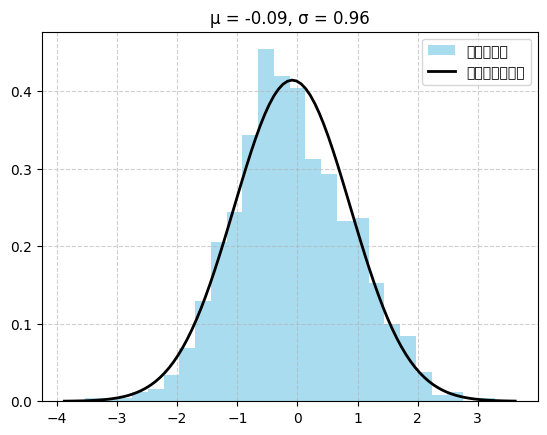

0.0016255538482572859


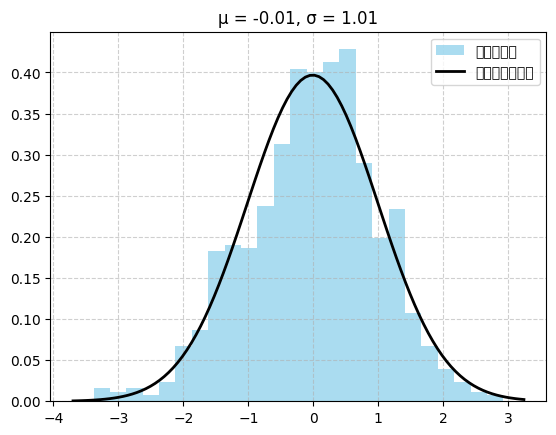

0.0013261047736985586


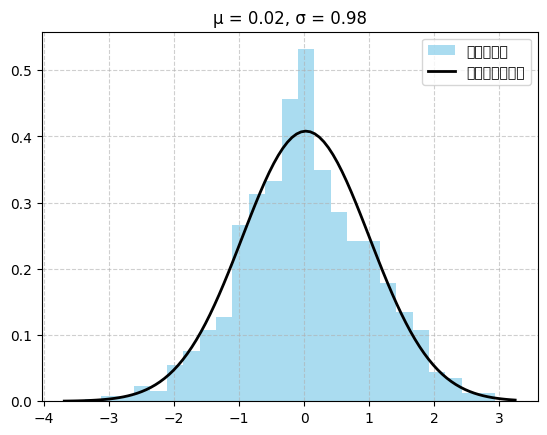

In [ ]:
for i in range(10000):
    d1arr = np.random.normal(loc=0.0, scale=1.0, size=1000)
    # d1arr=np.random.random(1000)
    _, p = fit_gaussian(d1arr)
    if p < 0.002:
        print(p)
        plot_gaussian(d1arr)